In [1]:
import keras
from keras.models import Sequential
from keras.layers import MaxPooling2D, Conv2D, Flatten, Dense, Dropout, BatchNormalization
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('dark_background')
from keras.utils import to_categorical
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [3]:
label_encoder = LabelEncoder()
label_encoder.fit(["Atopic Dermatitis", "Herpes", "Lyme disease", "Poison Ivy", "Psoriasis", "Rosacea"])
data =[]
labels=[]
for disease_folder in ["Atopic Dermatitis", "Herpes", "Lyme disease", "Poison Ivy", "Psoriasis", "Rosacea"]:
    class_index = label_encoder.transform([disease_folder])[0]
    class_label = to_categorical(class_index, num_classes=6)
    paths = []
    for r, d, f in os.walk(os.path.join(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Multiple-skin-diseases\Multiple-skin-diseases", disease_folder)):
        for file in f:
            if file.lower().endswith(('.jpg', '.jpeg')):
                paths.append(os.path.join(r, file))

        for path in paths:
            img = Image.open(path)
            img = img.resize((128, 128))
            img = np.array(img)
            if img.shape == (128, 128, 3):
                  data.append(img)
                  labels.append(class_label)
data = np.array(data)
labels = np.array(labels)

print(data.shape)
print(labels.shape)

(1642, 128, 128, 3)
(1642, 6)


In [4]:
data = np.array(data)
data.shape

(1642, 128, 128, 3)

In [5]:
result = np.array(labels)
result=result.reshape(1642, -1)

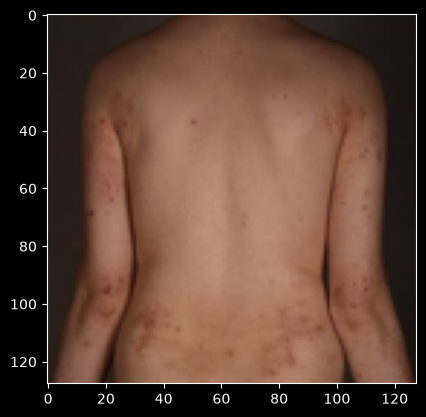

In [6]:
plt.imshow(data[10])

In [8]:
x_train,x_test,y_train,y_test = train_test_split(data,result, test_size=0.2, shuffle=True, random_state=42)

In [9]:
output_classes = 6

model = Sequential()

model.add(Conv2D(32, kernel_size=(2, 2), input_shape=(128, 128, 3), padding = 'Same'))
model.add(Conv2D(32, kernel_size=(2, 2),  activation ='relu', padding = 'Same'))
model.add(Dropout(0.45))

model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(64, kernel_size = (2,2), activation ='relu', padding = 'Same'))
model.add(Conv2D(64, kernel_size = (2,2), activation ='relu', padding = 'Same'))
model.add(Dropout(0.45))

model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))
model.add(Dropout(0.25))

model.add(Flatten())

model.add(Dense(512, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(6, activation='softmax'))

print(model.summary())

c:\Users\vimal_z0\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    33,554,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         3,078 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,587,654 (128.13 MB)

 Trainable params: 33,587,462 (128.13 MB)

 Non-trainable params: 192 (768.00 B)

None


In [10]:
model.compile(loss = "categorical_crossentropy", optimizer='Adam',metrics=['accuracy'])

In [11]:
x_train.shape

(1313, 128, 128, 3)

In [12]:
y_train.shape

(1313, 6)

In [13]:
history = model.fit(x_train, y_train, epochs = 10, batch_size = 20, verbose = 1,validation_data = (x_test, y_test))

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 155s 2s/step - accuracy: 0.2079 - loss: 12.7174 - val_accuracy: 0.2614 - val_loss: 2.7647
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 203s 2s/step - accuracy: 0.2490 - loss: 1.8154 - val_accuracy: 0.2523 - val_loss: 2.8011
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 103s 2s/step - accuracy: 0.2521 - loss: 1.7790 - val_accuracy: 0.2401 - val_loss: 3.0891
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 147s 2s/step - accuracy: 0.2468 - loss: 1.7623 - val_accuracy: 0.2888 - val_loss: 4.4953
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 98s 1s/step - accuracy: 0.2513 - loss: 1.7503 - val_accuracy: 0.1611 - val_loss: 4.0782
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 109s 2s/step - accuracy: 0.2780 - loss: 1.7134 - val_accuracy: 0.1185 - val_loss: 3.4825
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 157s 2s/step - accuracy: 0.2696 - loss: 1.7204 - val_accuracy: 0.2523 - val_loss: 2.9479
Epoch 8/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 149s 2s/step - accuracy: 0.2826 - loss: 1.7173 - val_accuracy: 0.2432 - v

In [14]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", test_accuracy)

11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 245ms/step - accuracy: 0.2188 - loss: 3.2030
Test Accuracy: 0.21884498000144958


In [15]:
def names(number):
    if number==0:
        return "Atopic Dermatitis"
    elif number==1:
        return "Herpes"
    elif number==2:
        return "Lyme disease"
    elif number==3:
        return "Poison Ivy"
    elif number==4:
        return "Psoriasis"
    else:
        return "Rosacea"

27.030165% Confidence This Is Herpes


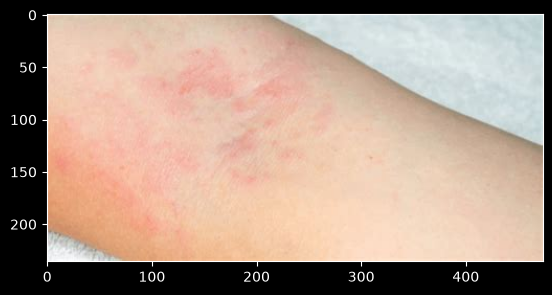

In [16]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Multiple-skin-diseases\Multiple-skin-diseases\Atopic Dermatitis\image11.jpg")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))

74.48483% Confidence This Is Psoriasis


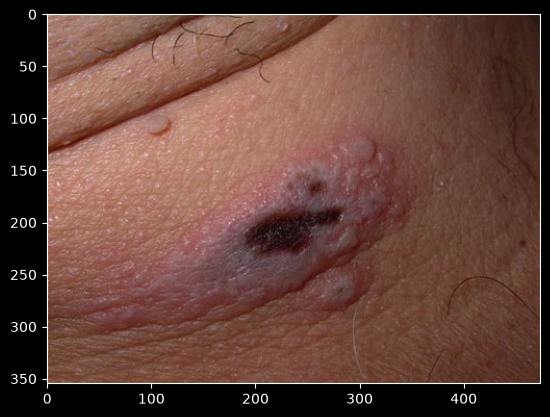

In [17]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Multiple-skin-diseases\Multiple-skin-diseases\Herpes\image6.jpg")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))

96.179085% Confidence This Is Atopic Dermatitis


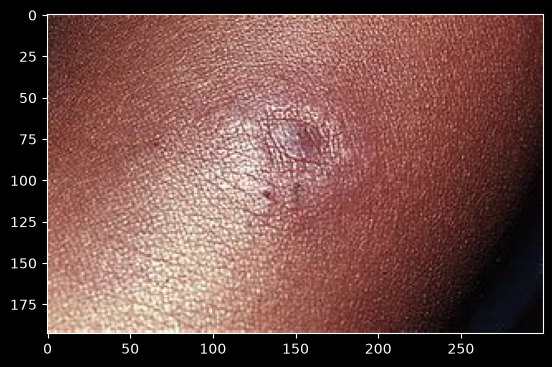

In [18]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Multiple-skin-diseases\Multiple-skin-diseases\Lyme disease\image8.jpg")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))

50.49517% Confidence This Is Poison Ivy


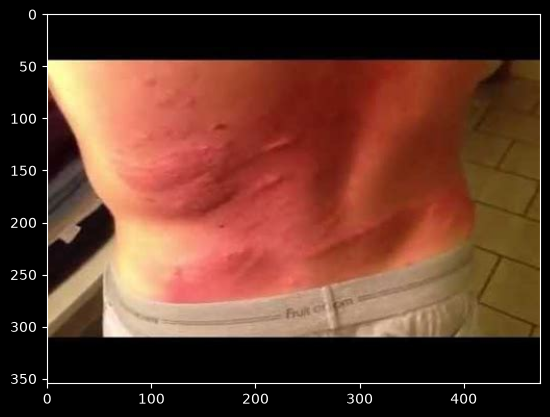

In [19]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Multiple-skin-diseases\Multiple-skin-diseases\Poison Ivy\image4.jpg")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))

99.997604% Confidence This Is Psoriasis


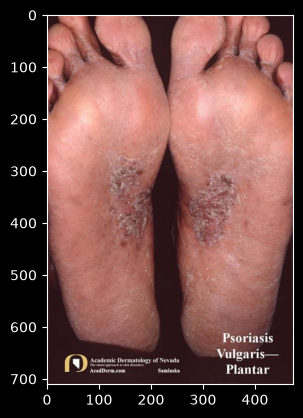

In [20]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Multiple-skin-diseases\Multiple-skin-diseases\Psoriasis\image6.jpg")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))

26.587868% Confidence This Is Lyme disease


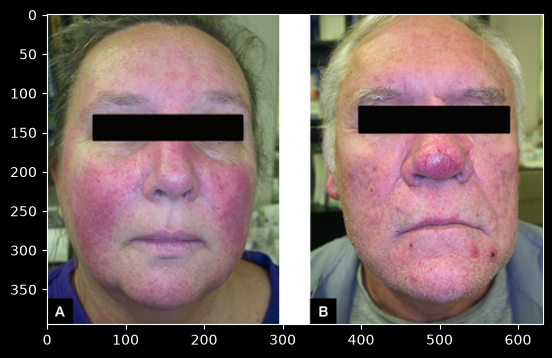

In [21]:
from matplotlib.pyplot import imshow

img = Image.open(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\DL_CNN_DataSets\Multiple-skin-diseases\Multiple-skin-diseases\Rosacea\AFP-Focus-Chong-Fig-1.jpg")
x = np.array(img.resize((128,128)))
x = x.reshape(-1,128,128,3)
res = model.predict_on_batch(x)
classification = np.where(res == np.amax(res))[1][0]
imshow(img)
print(str(res[0][classification]*100) + '% Confidence This Is ' + names(classification))